In [1]:
from src.dados import montar_painel, PASTA_PROCESSED, CHAVES_RECORTE

painel = montar_painel([2022, 2023, 2024, 2025])

PASTA_PROCESSED.mkdir(parents=True, exist_ok=True)
painel.to_parquet(PASTA_PROCESSED / "painel_mensal.parquet", index=False)

print(painel.shape)
painel.info(memory_usage="deep")

Baixando https://www.bcb.gov.br/pda/desig/scrdata_2022.zip ...
2022: 12 arquivos mensais
Baixando https://www.bcb.gov.br/pda/desig/scrdata_2023.zip ...
2023: 12 arquivos mensais
Baixando https://www.bcb.gov.br/pda/desig/scrdata_2024.zip ...
2024: 12 arquivos mensais
2025: 12 arquivos mensais
(28157, 11)
<class 'pandas.DataFrame'>
RangeIndex: 28157 entries, 0 to 28156
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   data_base                  28157 non-null  datetime64[us]
 1   uf                         28157 non-null  category      
 2   cliente                    28157 non-null  category      
 3   modalidade                 28157 non-null  category      
 4   carteira_ativa             28157 non-null  float64       
 5   carteira_inadimplencia     28157 non-null  float64       
 6   carteira_a_vencer          28157 non-null  float64       
 7   a_vencer_ate_90_dias     

In [3]:
print("Meses por ano:")
print(painel["data_base"].dt.year.value_counts().sort_index(), "\n")

grupos = painel.groupby(CHAVES_RECORTE, observed=True)
print(f"Recortes com dados: {grupos.ngroups}")
print("Meses por recorte:")
print(grupos.size().describe())

Meses por ano:
data_base
2022    7108
2023    7062
2024    7016
2025    6971
Name: count, dtype: int64 

Recortes com dados: 624
Meses por recorte:
count    624.000000
mean      45.123397
std        9.178933
min        1.000000
25%       48.000000
50%       48.000000
75%       48.000000
max       48.000000
dtype: float64


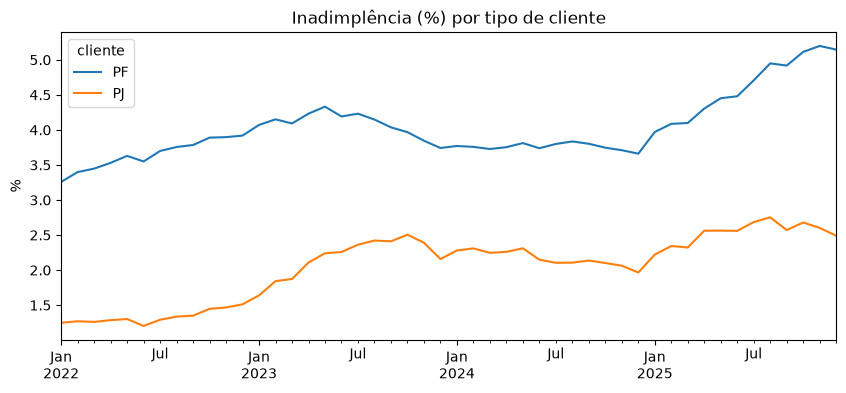

In [4]:
import matplotlib.pyplot as plt

nacional = painel.groupby(["data_base", "cliente"], observed=True)[["carteira_inadimplencia", "carteira_ativa"]].sum()
nacional["inadimplencia_%"] = 100 * nacional["carteira_inadimplencia"] / nacional["carteira_ativa"]

nacional["inadimplencia_%"].unstack("cliente").plot(figsize=(10, 4), title="Inadimplência (%) por tipo de cliente")
plt.ylabel("%")
plt.xlabel("")
plt.show()

In [5]:
ultimo = painel[painel["data_base"] == painel["data_base"].max()]
carteira_mi = ultimo["carteira_ativa"] / 1e6

print("Carteira por recorte no último mês (R$ milhões):")
print(carteira_mi.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1))
for limite in (1, 10, 50):
    print(f"Recortes com menos de R$ {limite} mi: {(carteira_mi < limite).sum()} de {len(carteira_mi)}")

Carteira por recorte no último mês (R$ milhões):
count       581.0
mean      12812.9
std       38796.1
min           0.0
10%           1.6
25%          36.5
50%         977.4
75%        9688.4
90%       32295.6
max      476405.4
Name: carteira_ativa, dtype: float64
Recortes com menos de R$ 1 mi: 52 de 581
Recortes com menos de R$ 10 mi: 99 de 581
Recortes com menos de R$ 50 mi: 161 de 581


In [6]:
# Critérios para um recorte entrar no modelo
CARTEIRA_MINIMA = 100e6  # R$ 100 milhões de carteira ativa (mediana no período)
MESES_MINIMOS = 48       # histórico completo: 12 meses x 4 anos (2022 a 2025)

# Uma linha por recorte, com o número de meses e a carteira mediana
resumo = painel.groupby(CHAVES_RECORTE, observed=True).agg(
    meses=("data_base", "size"),
    carteira_mediana=("carteira_ativa", "median"),
)

# True para os recortes que passam nos dois critérios
manter = (resumo["meses"] >= MESES_MINIMOS) & (resumo["carteira_mediana"] >= CARTEIRA_MINIMA)
recortes_ok = resumo[manter].reset_index()[CHAVES_RECORTE]

# O merge "inner" mantém no painel só as linhas dos recortes aprovados
painel_filtrado = painel.merge(recortes_ok, on=CHAVES_RECORTE, how="inner")

print(f"Recortes mantidos: {len(recortes_ok)} de {len(resumo)}")
print(f"Linhas: {len(painel_filtrado)}")
print(recortes_ok["cliente"].value_counts())

painel_filtrado.to_parquet(PASTA_PROCESSED / "painel_filtrado.parquet", index=False)

Recortes mantidos: 386 de 624
Linhas: 18528
cliente
PJ    230
PF    156
Name: count, dtype: int64
